# Data Challenge - Recomendação de Cultivo Inteligente

## Análise exploratória e primeiro experimento

Este notebook documenta o desenvolvimento do **Desafio 2 - Recomendação de Cultivo Inteligente**. O objetivo é classificar uma cultura agrícola entre 22 possibilidades usando sete variáveis de solo e microclima.

## Organização da análise

1. definição do problema e do critério de sucesso;
2. acesso reproduzível à fonte de dados;
3. diagnóstico de qualidade e análise exploratória;
4. preparação dos dados sem vazamento entre treino e teste;
5. comparação de modelos e avaliação do primeiro experimento;
6. interpretação dos resultados, limitações e próximos passos.

Os arquivos gerados são organizados nas pastas `figures`, `results` e `models` do projeto.

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score
)
from sklearn.model_selection import (
    StratifiedKFold, cross_validate, train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.exceptions import UndefinedMetricWarning

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
TARGET = "label"
print("Ambiente preparado.")

# Pastas do projeto. O notebook funciona quando aberto em notebooks/ ou na raiz.
CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
DATA_DIR = PROJECT_ROOT / "data"
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = PROJECT_ROOT / "models"
for directory in (DATA_DIR, FIGURES_DIR, RESULTS_DIR, MODELS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"Raiz do projeto: {PROJECT_ROOT}")

Ambiente preparado.
Raiz do projeto: C:\Users\Guilherme_Zanini\Documents\github\pos-engenharia-ciencia-dados\data-challenge-cultivo-inteligente


## 1. Aquisição da base pelo Hugging Face

Nesta etapa, o notebook faz a ingestão de um dataset público: consulta a API do Hugging Face, identifica o CSV disponível no repositório e carrega os registros com `pandas`.

Também são registrados o identificador do dataset, o arquivo selecionado e a revisão informada pela API.

In [2]:
from urllib.request import urlopen

DATASET_ID = "randalakab/Crop-recommendation"
API_URL = f"https://huggingface.co/api/datasets/{DATASET_ID}"
LOCAL_FALLBACK = DATA_DIR / "crop_recommendation.csv"

try:
    with urlopen(API_URL, timeout=30) as response:
        dataset_info = json.load(response)
    csv_files = [item["rfilename"] for item in dataset_info["siblings"]
                 if item["rfilename"].lower().endswith(".csv")]
    if not csv_files:
        raise FileNotFoundError("A API não informou nenhum arquivo CSV no dataset.")
    selected_file = csv_files[0]
    data_source = f"https://huggingface.co/datasets/{DATASET_ID}/resolve/main/{selected_file}"
    df = pd.read_csv(data_source)
    print(f"Fonte: API do Hugging Face → {selected_file}")
except Exception as error:
    if not LOCAL_FALLBACK.exists():
        raise
    data_source = str(LOCAL_FALLBACK)
    df = pd.read_csv(LOCAL_FALLBACK)
    print(f"API indisponível ({error}). Usando contingência local: {LOCAL_FALLBACK}")

print(f"Dimensões: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
display(df.head())

Fonte: API do Hugging Face → crop_recommendation.csv
Dimensões: 2,200 linhas x 8 colunas


,N,P,K,temperature,humidity,ph,rainfall,label
0,93.183761,27.250831,74.277207,33.674623,94.914503,6.484254,32.683787,muskmelon
1,96.207721,19.879799,58.311558,30.074946,87.959344,6.755477,41.108275,watermelon
2,43.282444,20.270145,46.187129,34.166159,100.166220,7.390471,197.558965,papaya
3,59.798590,4.900153,41.490719,26.914239,92.876518,6.929745,147.476051,papaya
4,6.924168,137.545829,169.587918,23.536649,94.791895,5.777406,192.413493,apple


In [3]:
provenance = pd.Series({
    "dataset": DATASET_ID,
    "arquivo": selected_file if "selected_file" in globals() else LOCAL_FALLBACK.name,
    "revisao_api": dataset_info.get("sha", "não informada") if "dataset_info" in globals() else "contingência local",
    "ultima_modificacao_api": dataset_info.get("lastModified", "não informada") if "dataset_info" in globals() else "contingência local",
    "fonte_carregada": data_source,
}, name="valor")
display(provenance.to_frame())

,valor
dataset,randalakab/Crop-recommendation
arquivo,crop_recommendation.csv
revisao_api,f154ba9e2c812c86ec6e24e9bfa14803d6db9689
ultima_modificacao_api,2026-03-18T05:15:09.000Z
fonte_carregada,https://huggingface.co/datasets/randalakab/Cro...


## 2. Diagnóstico da base

O diagnóstico verifica a estrutura das colunas, os tipos, valores ausentes, duplicidades, quantidade de culturas, equilíbrio das classes e valores que exigem investigação. Esse procedimento descreve a base recebida; ele não corrige automaticamente observações sem uma justificativa documentada.

| Campo | Interpretação usada no projeto | Unidade informada na fonte |
|---|---|---|
| N, P e K | nutrientes do solo | não documentada |
| temperature | temperatura | não documentada |
| humidity | umidade | não documentada |
| ph | acidez ou alcalinidade do solo | escala de pH |
| rainfall | precipitação | não documentada |
| label | cultura recomendada | categoria |

In [4]:
quality = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "ausentes": df.isna().sum(),
    "unicos": df.nunique(),
})
display(quality)
print(f"Linhas duplicadas: {df.duplicated().sum()}")
print(f"Culturas: {df[TARGET].nunique()}")
print(f"Registros com umidade > 100%: {(df['humidity'] > 100).sum()}")

diagnostic_summary = pd.Series({
    "registros": len(df),
    "colunas": df.shape[1],
    "valores_ausentes": int(df.isna().sum().sum()),
    "linhas_duplicadas": int(df.duplicated().sum()),
    "culturas": int(df[TARGET].nunique()),
    "menor_classe": int(df[TARGET].value_counts().min()),
    "maior_classe": int(df[TARGET].value_counts().max()),
    "umidade_acima_de_100": int((df["humidity"] > 100).sum()),
}, name="resultado")
display(diagnostic_summary.to_frame())

,tipo,ausentes,unicos
N,float64,0,2180
P,float64,0,2200
K,float64,0,2200
temperature,float64,0,2200
humidity,float64,0,2200
ph,float64,0,2200
rainfall,float64,0,2200
label,str,0,22


Linhas duplicadas: 0
Culturas: 22
Registros com umidade > 100%: 19


,resultado
registros,2200
colunas,8
valores_ausentes,0
linhas_duplicadas,0
culturas,22
menor_classe,100
maior_classe,100
umidade_acima_de_100,19


In [5]:
summary = df[FEATURES].describe().T
summary["amplitude"] = summary["max"] - summary["min"]
display(summary.round(3))

,count,mean,std,min,25%,50%,75%,max,amplitude
N,2200.0,48.250,39.374,0.000,14.690,32.006,85.446,140.722,140.722
P,2200.0,48.450,31.712,0.000,23.449,44.604,61.332,152.116,152.116
K,2200.0,61.043,42.319,2.675,41.750,51.425,61.204,240.580,237.905
temperature,2200.0,25.574,6.233,0.828,22.011,26.123,29.622,41.728,40.901
humidity,2200.0,72.559,22.626,13.607,61.604,79.960,89.679,101.362,87.756
ph,2200.0,6.419,0.684,3.557,6.046,6.425,6.863,8.022,4.465
rainfall,2200.0,114.365,61.199,18.264,65.521,99.128,157.753,301.955,283.691


### Distribuição das classes

label,apple,banana,blackgram,chickpea,coconut,coffee,cotton,grapes,jute,kidneybeans,...,mango,mothbeans,mungbean,muskmelon,orange,papaya,pigeonpeas,pomegranate,rice,watermelon
registros,100,100,100,100,100,100,100,100,100,100,...,100,100,100,100,100,100,100,100,100,100


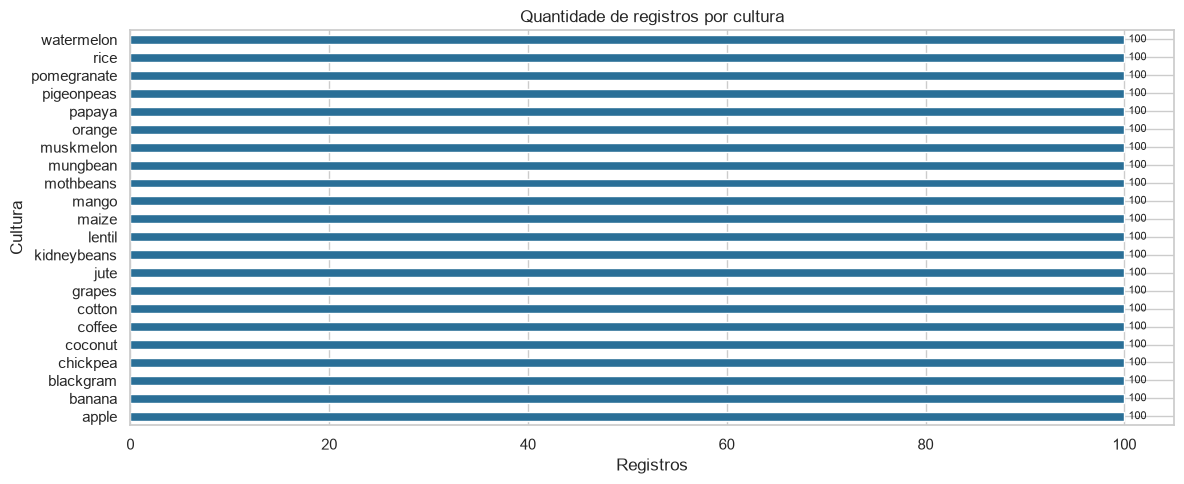

In [6]:
class_counts = df[TARGET].value_counts().sort_index()
display(class_counts.to_frame("registros").T)

fig, ax = plt.subplots(figsize=(12, 5))
class_counts.sort_values().plot.barh(ax=ax, color="#2A6F97")
ax.set(title="Quantidade de registros por cultura", xlabel="Registros", ylabel="Cultura")
ax.bar_label(ax.containers[0], padding=3, fontsize=8)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "distribuicao_classes.png", dpi=180, bbox_inches="tight")
plt.show()

As classes possuem a mesma quantidade de registros. Portanto, acurácia não fica distorcida por desbalanceamento neste conjunto, mas a métrica **F1 macro** será mantida por ser adequada a problemas multiclasse.

## 3. Análise exploratória

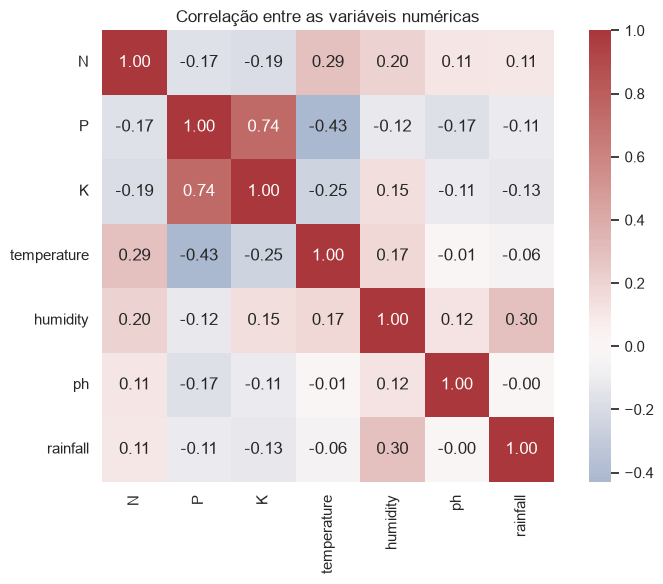

In [7]:
corr = df[FEATURES].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, ax=ax)
ax.set_title("Correlação entre as variáveis numéricas")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "correlacao_variaveis.png", dpi=180, bbox_inches="tight")
plt.show()

A correlação linear entre variáveis não mostra, sozinha, o poder de separação entre culturas. Para uma leitura inicial, calculamos o **eta quadrado**: a proporção da variância de cada atributo associada às diferenças entre as classes. É um indicador exploratório, não uma prova causal.

,eta_quadrado
K,0.9461
humidity,0.9435
N,0.9305
P,0.9106
rainfall,0.8174
temperature,0.5752
ph,0.4641


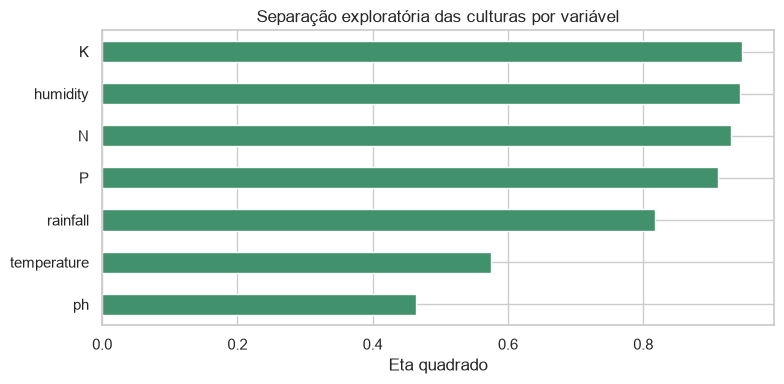

In [8]:
def eta_squared(data, feature, target):
    overall = data[feature].mean()
    total = ((data[feature] - overall) ** 2).sum()
    between = sum(
        len(group) * (group[feature].mean() - overall) ** 2
        for _, group in data.groupby(target)
    )
    return between / total if total else np.nan

eta = pd.Series(
    {feature: eta_squared(df, feature, TARGET) for feature in FEATURES},
    name="eta_quadrado",
).sort_values(ascending=False)
display(eta.to_frame().round(4))

fig, ax = plt.subplots(figsize=(8, 4))
eta.sort_values().plot.barh(ax=ax, color="#40916C")
ax.set(title="Separação exploratória das culturas por variável", xlabel="Eta quadrado", ylabel="")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "eta_quadrado_variaveis.png", dpi=180, bbox_inches="tight")
plt.show()

### Verificação da umidade acima de 100%

,N,P,K,temperature,humidity,ph,rainfall,label
2149,14.803819,149.121607,147.057008,14.764585,101.362240,5.643967,169.286577,apple
1293,24.307783,19.123312,42.473961,33.540762,101.191800,5.530988,146.024671,coconut
1419,8.696370,13.530375,15.969660,10.210177,101.146861,6.273814,148.437585,orange
376,16.741278,139.066097,176.448148,10.344184,100.725121,6.334881,130.829449,apple
1149,115.389101,12.639566,53.772282,37.640039,100.698368,6.059751,32.738388,muskmelon
508,43.467672,9.558881,56.667697,37.883718,100.676138,6.939354,104.455039,papaya
651,68.203988,7.140359,40.641077,28.029511,100.621739,7.482378,166.517754,papaya
2044,9.960152,9.801056,11.864105,28.691512,100.596350,7.070096,186.137927,orange
1677,29.932057,15.351319,58.786580,26.324554,100.574521,6.731762,104.613829,coconut
753,6.981524,9.940116,13.441539,16.189667,100.551704,7.216624,117.114812,orange


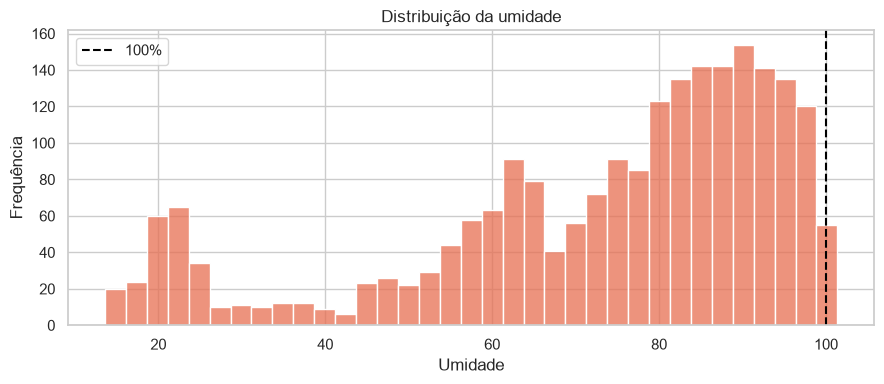

In [9]:
humidity_outliers = df.loc[df["humidity"] > 100].sort_values("humidity", ascending=False)
display(humidity_outliers)

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(df["humidity"], bins=35, ax=ax, color="#E76F51")
ax.axvline(100, color="black", linestyle="--", label="100%")
ax.set(title="Distribuição da umidade", xlabel="Umidade", ylabel="Frequência")
ax.legend()
plt.tight_layout()
fig.savefig(FIGURES_DIR / "distribuicao_umidade.png", dpi=180, bbox_inches="tight")
plt.show()

Os valores superiores a 100% são fisicamente questionáveis se a variável representar umidade relativa do ar. Eles são mantidos no cenário principal para preservar a base original. Depois, uma análise de sensibilidade compara o desempenho com e sem esses registros.

## 4. Preparação e comparação de modelos

In [10]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Treino: {len(X_train)} registros | Teste: {len(X_test)} registros")
print(f"Classes no treino: {y_train.nunique()} | Classes no teste: {y_test.nunique()}")

Treino: 1760 registros | Teste: 440 registros
Classes no treino: 22 | Classes no teste: 22


In [11]:
models = {
    "Baseline (classe mais frequente)": DummyClassifier(strategy="most_frequent"),
    "Regressão logística": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
    ]),
    "Árvore de decisão": DecisionTreeClassifier(
        max_depth=10, min_samples_leaf=2, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=400, min_samples_leaf=1, n_jobs=-1,
        random_state=RANDOM_STATE
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
}

cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_rows.append({
        "modelo": name,
        "acuracia_media": scores["test_accuracy"].mean(),
        "acuracia_dp": scores["test_accuracy"].std(),
        "f1_macro_media": scores["test_f1_macro"].mean(),
        "f1_macro_dp": scores["test_f1_macro"].std(),
        "precisao_macro_media": scores["test_precision_macro"].mean(),
        "recall_macro_media": scores["test_recall_macro"].mean(),
    })

cv_results = pd.DataFrame(cv_rows).sort_values("f1_macro_media", ascending=False)
display(cv_results.round(4))

,modelo,acuracia_media,acuracia_dp,f1_macro_media,f1_macro_dp,precisao_macro_media,recall_macro_media
3,Random Forest,0.9653,0.0068,0.9652,0.0069,0.9673,0.9653
1,Regressão logística,0.9267,0.0105,0.9254,0.0108,0.9294,0.9267
2,Árvore de decisão,0.9102,0.0069,0.9096,0.0067,0.9170,0.9102
0,Baseline (classe mais frequente),0.0455,0.0000,0.0040,0.0000,0.0021,0.0455


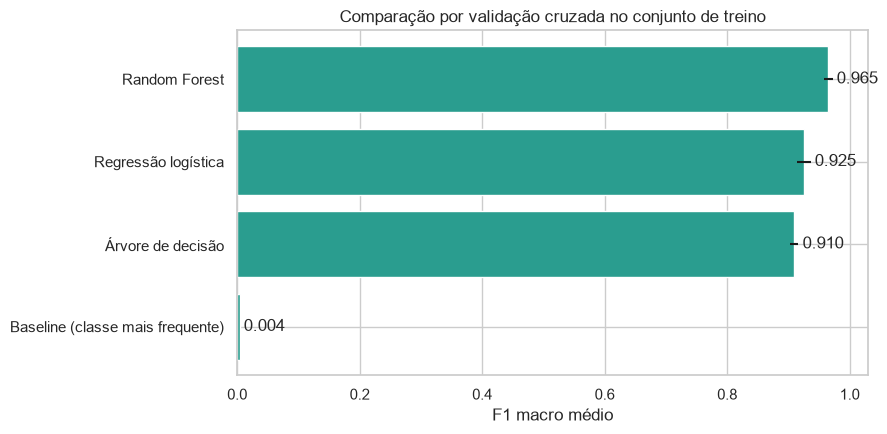

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_data = cv_results.sort_values("f1_macro_media")
ax.barh(plot_data["modelo"], plot_data["f1_macro_media"], xerr=plot_data["f1_macro_dp"], color="#2A9D8F")
ax.set(title="Comparação por validação cruzada no conjunto de treino", xlabel="F1 macro médio", ylabel="")
ax.set_xlim(0, 1.03)
for container in ax.containers:
    if hasattr(container, "datavalues"):
        ax.bar_label(container, fmt="%.3f", padding=3)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "comparacao_modelos.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Avaliação final no conjunto de teste

In [13]:
best_name = cv_results.iloc[0]["modelo"]
best_model = clone(models[best_name])
best_model.fit(X_train, y_train)
pred = best_model.predict(X_test)

test_metrics = pd.Series({
    "modelo_selecionado": best_name,
    "acuracia": accuracy_score(y_test, pred),
    "acuracia_balanceada": balanced_accuracy_score(y_test, pred),
    "precisao_macro": precision_score(y_test, pred, average="macro", zero_division=0),
    "recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
    "f1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
    "f1_weighted": f1_score(y_test, pred, average="weighted", zero_division=0),
})
display(test_metrics.to_frame("resultado"))

report = pd.DataFrame(classification_report(y_test, pred, output_dict=True, zero_division=0)).T
display(report.round(3))

,resultado
modelo_selecionado,Random Forest
acuracia,0.972727
acuracia_balanceada,0.972727
precisao_macro,0.974366
recall_macro,0.972727
f1_macro,0.972464
f1_weighted,0.972464


,precision,recall,f1-score,support
apple,1.000,1.000,1.000,20.000
banana,0.952,1.000,0.976,20.000
blackgram,0.952,1.000,0.976,20.000
chickpea,0.792,0.950,0.864,20.000
coconut,0.952,1.000,0.976,20.000
coffee,1.000,1.000,1.000,20.000
cotton,1.000,1.000,1.000,20.000
grapes,1.000,1.000,1.000,20.000
jute,0.950,0.950,0.950,20.000
kidneybeans,0.938,0.750,0.833,20.000


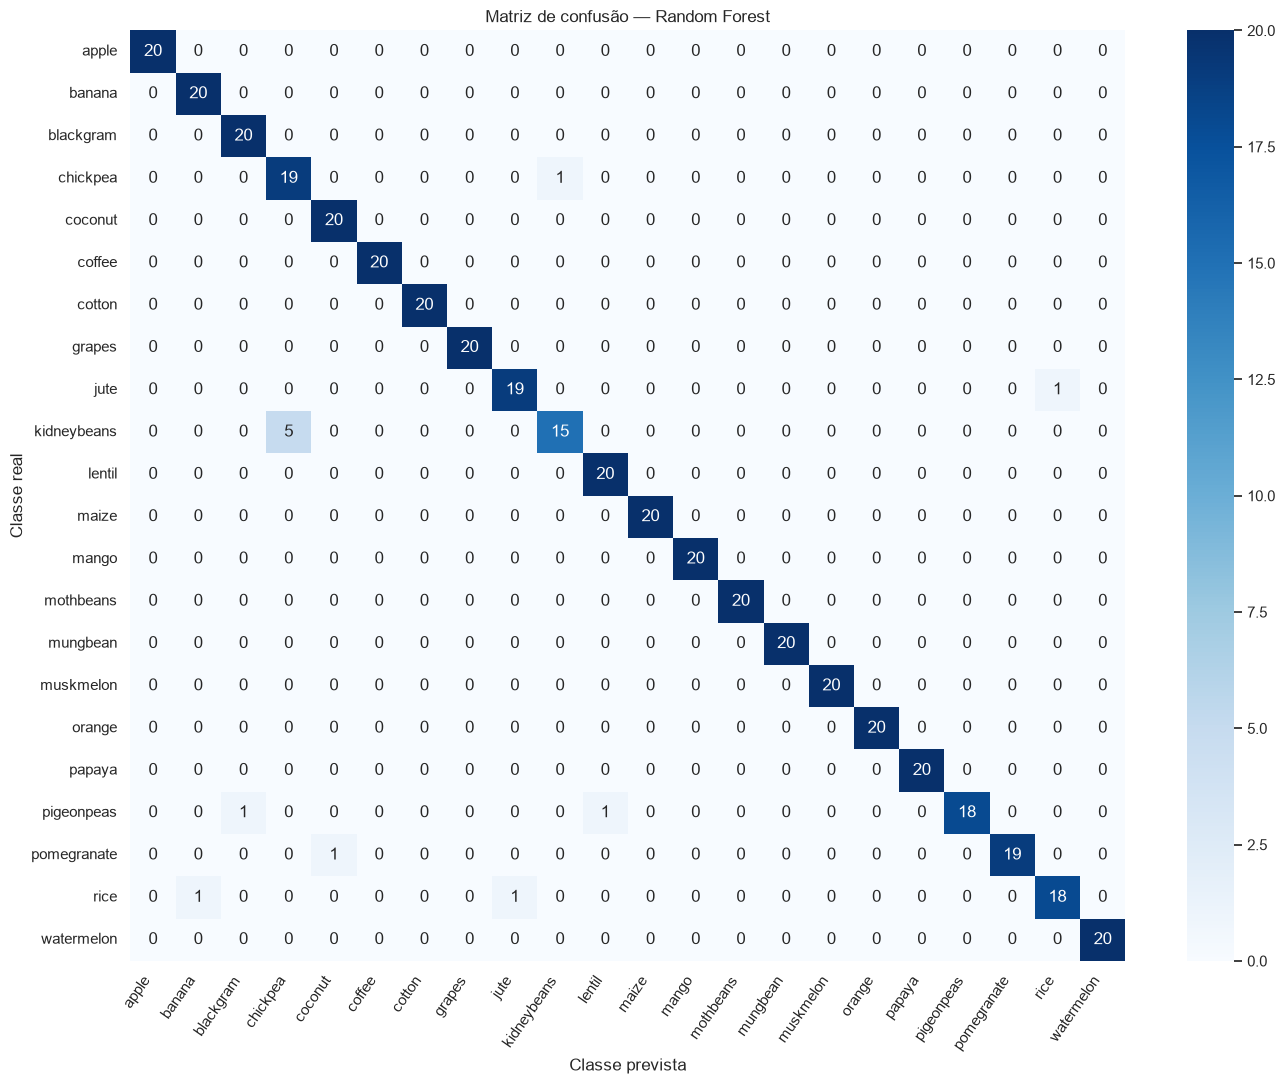

In [14]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, pred, labels=labels)
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax)
ax.set(title=f"Matriz de confusão — {best_name}", xlabel="Classe prevista", ylabel="Classe real")
plt.xticks(rotation=55, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "matriz_confusao.png", dpi=180, bbox_inches="tight")
plt.show()

### Importância das variáveis

,importancia
humidity,0.2384
P,0.1616
rainfall,0.1586
N,0.1492
K,0.1251
ph,0.0905
temperature,0.0767


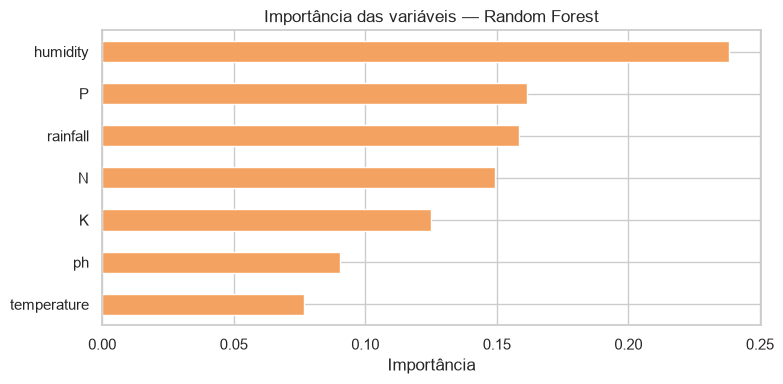

In [15]:
if hasattr(best_model, "feature_importances_"):
    importance = pd.Series(best_model.feature_importances_, index=FEATURES).sort_values(ascending=False)
    display(importance.to_frame("importancia").round(4))
    fig, ax = plt.subplots(figsize=(8, 4))
    importance.sort_values().plot.barh(ax=ax, color="#F4A261")
    ax.set(title=f"Importância das variáveis — {best_name}", xlabel="Importância", ylabel="")
    plt.tight_layout()
    fig.savefig(FIGURES_DIR / "importancia_variaveis.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("O modelo selecionado não fornece importância nativa de variáveis.")

## 6. Análise de sensibilidade da umidade

In [16]:
filtered = df.loc[df["humidity"] <= 100].copy()
X_filtered = filtered[FEATURES]
y_filtered = filtered[TARGET]

full_scores = cross_validate(
    clone(best_model), X, y, cv=cv, scoring="f1_macro", n_jobs=1
)["test_score"]
filtered_scores = cross_validate(
    clone(best_model), X_filtered, y_filtered, cv=cv, scoring="f1_macro", n_jobs=1
)["test_score"]

sensitivity = pd.DataFrame({
    "cenario": ["Base completa", "Sem umidade > 100%"],
    "registros": [len(df), len(filtered)],
    "f1_macro_medio": [full_scores.mean(), filtered_scores.mean()],
    "f1_macro_dp": [full_scores.std(), filtered_scores.std()],
})
display(sensitivity.round(4))

,cenario,registros,f1_macro_medio,f1_macro_dp
0,Base completa,2200,0.9680,0.0058
1,Sem umidade > 100%,2181,0.9712,0.0101


A comparação acima mede apenas a sensibilidade preditiva. Mesmo que o desempenho mude pouco, a validade física da variável continua exigindo confirmação da origem e da unidade de medida.

## 7. Exportação dos resultados

In [17]:
cv_results.to_csv(RESULTS_DIR / "resultados_validacao_cruzada.csv", index=False)
report.to_csv(RESULTS_DIR / "relatorio_classificacao_teste.csv")
sensitivity.to_csv(RESULTS_DIR / "sensibilidade_umidade.csv", index=False)
joblib.dump(best_model, MODELS_DIR / "modelo_cultivo_selecionado.joblib")

metadata = {
    "dataset": DATASET_ID,
    "fonte_carregada": data_source,
    "modelo": best_name,
    "features": FEATURES,
    "target": TARGET,
    "random_state": RANDOM_STATE,
    "registros": len(df),
    "classes": int(df[TARGET].nunique()),
    "metricas_teste": {
        key: (float(value) if key != "modelo_selecionado" else value)
        for key, value in test_metrics.items()
    },
}
(RESULTS_DIR / "metadados_modelo.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Figuras, tabelas e modelo exportados nas pastas do projeto.")

Figuras, tabelas e modelo exportados nas pastas do projeto.


## 8. Conclusões e próximos passos

- A base permite formular um problema multiclasse com 22 culturas e sete atributos.
- O balanceamento das classes simplifica a comparação, mas não substitui validação fora da amostra.
- A escolha do modelo é baseada em F1 macro médio na validação cruzada do treino.
- O conjunto de teste permanece separado até a avaliação final.